# Projet final : les récoltes agricoles

**Équipe :** The Pythonists (Kielel et équipe)

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **notre démarche rigoureuse d'analyse de données** : chaque étape formule l'objectif recherché, le code exécuté, le résultat obtenu et les conclusions opérationnelles.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Configuration du style graphique
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.size'] = 10

brut = pd.read_csv("donnees/recoltes_brut.csv")
print("Dimensions initiales du jeu de données brut :", brut.shape)
print("Colonnes disponibles :", list(brut.columns))


Dimensions initiales du jeu de données brut : (408, 6)
Colonnes disponibles : ['annee', 'saison', 'departement', 'culture', 'surface_ha', 'production_t']


## 1. Diagnostic

Nous examinons la forme du tableau, les types de colonnes, les valeurs manquantes, les doublons éventuels, ainsi que l'ensemble des graphies et écritures distinctes dans les colonnes qualitatives (`saison`, `departement`, `culture`).


In [2]:
# Aperçu général et types de données
print("--- Informations sur les types et valeurs non nulles ---")
brut.info()


--- Informations sur les types et valeurs non nulles ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   annee         408 non-null    int64 
 1   saison        408 non-null    object
 2   departement   408 non-null    object
 3   culture       408 non-null    object
 4   surface_ha    408 non-null    object
 5   production_t  393 non-null    object
dtypes: int64(1), object(5)
memory usage: 19.3+ KB


In [3]:
# Recherche des valeurs manquantes et des doublons stricts
print("--- Valeurs manquantes par colonne ---")
print(brut.isna().sum())

print("\nNombre de lignes en double exactes :", brut.duplicated().sum())


--- Valeurs manquantes par colonne ---
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64

Nombre de lignes en double exactes : 18


In [4]:
# Analyse des écritures dans les colonnes textuelles
print("Saisons uniques :", brut['saison'].unique().tolist())
print("\nNombre d'écritures de départements :", brut['departement'].nunique())
print("Départements uniques bruts :\n", brut['departement'].unique().tolist())
print("\nNombre d'écritures de cultures :", brut['culture'].nunique())
print("Cultures uniques brutes :\n", brut['culture'].unique().tolist())


Saisons uniques : ['Printemps', 'Automne']

Nombre d'écritures de départements : 44
Départements uniques bruts :
 ['Ouest', 'Ouest ', 'ouest', 'Artibonite', 'Nord', 'Sud', 'Centre', ' Centre', 'NORD-OUEST', 'Nord-Ouest', 'Sud-Est', 'Sud-Est ', "Grand'Anse", "grand'anse", "GRAND'ANSE", 'Nord-Est', 'Nippes', 'NIPPES', 'ARTIBONITE', 'NORD', 'nord', 'Nord-Ouest ', 'nord-ouest', ' Nord-Ouest', ' Sud-Est', " Grand'Anse", "Grand'Anse ", 'Nord-Est ', 'Nippes ', 'OUEST', ' Artibonite', 'Nord ', ' Sud', 'sud-est', 'nord-est', 'NORD-EST', ' Ouest', 'SUD', 'artibonite', ' Nord', 'Sud ', 'sud', 'centre', ' Nord-Est']

Nombre d'écritures de cultures : 33
Cultures uniques brutes :
 [' Maïs', 'Sorgho', 'Riz', 'Haricot', 'Pois congo', 'banane', 'Igname', 'maïs', 'Banane', 'Maïs', 'IGNAME', ' Pois congo', 'MAÏS', 'Haricot ', 'Igname ', 'POIS CONGO', ' Igname', ' Sorgho', ' Haricot', 'HARICOT', 'Maïs ', 'igname', 'haricot', 'Sorgho ', 'Pois congo ', 'SORGHO', 'sorgho', ' Banane', 'pois congo', 'Riz ', ' 

In [5]:
# Examen des anomalies dans les colonnes numériques stockées en texte (object)
print("Exemples de valeurs problématiques dans 'surface_ha' :")
valeurs_anom_surf = [v for v in brut['surface_ha'].dropna().unique() if not str(v).replace('.', '', 1).isdigit()]
print(valeurs_anom_surf[:10])

print("\nExemples de valeurs problématiques dans 'production_t' :")
valeurs_anom_prod = [v for v in brut['production_t'].dropna().unique() if not str(v).replace('.', '', 1).isdigit()]
print(valeurs_anom_prod[:10])


Exemples de valeurs problématiques dans 'surface_ha' :
['2 517', '541 ha', '1 127', '1 185', '1 748', '492 ha', '997 ha', '1 050', '1 270', '873 ha']

Exemples de valeurs problématiques dans 'production_t' :
['3753 t', '2299 t', '1306 t', '2394 t', '599 t', '767 t', '8147 t', '2089 t', '3424 t', '520 t']


**Bilan du diagnostic :**
1. **`departement` et `culture`** : présence d'espaces superflus en début/fin de chaîne et de casses disparates (ex: `Maïs`, `maïs`, `MAÏS`, `Grand'Anse`, `GRAND'ANSE`, `grand'anse`).
2. **`surface_ha`** : de type texte avec des séparateurs d'espaces pour les milliers (ex: `'2 517'`) et des mentions d'unités `' ha'`.
3. **`production_t`** : de type texte avec des mentions d'unités `' t'`, et 15 valeurs manquantes (`NaN`).
4. **Doublons** : 18 lignes en doublon exact dans le fichier brut.


## 2. Nettoyage

Nous créons une copie `propre` et corrigeons chaque problème identifié pas à pas, en mesurant l'impact sur le nombre de lignes.

**Contrôle attendu :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.


In [6]:
# Copie de travail
propre = brut.copy()
print(f"Lignes au départ : {len(propre)}")


Lignes au départ : 408


In [7]:
# 1. Nettoyage des chaînes de caractères (espaces et casse)
# On supprime les espaces périphériques et on standardise en format Titre
propre['departement'] = propre['departement'].astype(str).str.strip().str.title()

# Pour la culture, on standardise en titre et on conserve la casse officielle de 'Pois congo'
propre['culture'] = propre['culture'].astype(str).str.strip().str.title().replace({'Pois Congo': 'Pois congo'})

print("Nombre de départements après harmonisation :", propre['departement'].nunique())
print("Départements obtenus :", sorted(propre['departement'].unique()))
print("\nNombre de cultures après harmonisation :", propre['culture'].nunique())
print("Cultures obtenues :", sorted(propre['culture'].unique()))


Nombre de départements après harmonisation : 10
Départements obtenus : ['Artibonite', 'Centre', "Grand'Anse", 'Nippes', 'Nord', 'Nord-Est', 'Nord-Ouest', 'Ouest', 'Sud', 'Sud-Est']

Nombre de cultures après harmonisation : 7
Cultures obtenues : ['Banane', 'Haricot', 'Igname', 'Maïs', 'Pois congo', 'Riz', 'Sorgho']


In [8]:
# 2. Nettoyage et conversion des colonnes numériques
# 'surface_ha' : suppression des espaces et du suffixe ' ha', conversion en entier
propre['surface_ha'] = (
    propre['surface_ha']
    .astype(str)
    .str.replace(" ha", "", regex=False)
    .str.replace(" ", "", regex=False)
    .astype(int)
)

# 'production_t' : suppression du suffixe ' t' et des espaces, conversion en float
propre['production_t'] = (
    propre['production_t']
    .astype(str)
    .str.replace(" t", "", regex=False)
    .str.replace(" ", "", regex=False)
    .replace('nan', None)
)
propre['production_t'] = pd.to_numeric(propre['production_t'])

print("Types de données après conversion :")
print(propre.dtypes)


Types de données après conversion :
annee             int64
saison           object
departement      object
culture          object
surface_ha        int64
production_t    float64
dtype: object


In [9]:
# 3. Traitement des valeurs manquantes (NaN)
lignes_avant_na = len(propre)
propre = propre.dropna()
lignes_apres_na = len(propre)
print(f"Suppression des valeurs manquantes : {lignes_avant_na} -> {lignes_apres_na} (-{lignes_avant_na - lignes_apres_na} lignes)")


Suppression des valeurs manquantes : 408 -> 393 (-15 lignes)


In [10]:
# 4. Traitement des doublons
lignes_avant_dedup = len(propre)
propre = propre.drop_duplicates()
lignes_apres_dedup = len(propre)
print(f"Suppression des doublons : {lignes_avant_dedup} -> {lignes_apres_dedup} (-{lignes_avant_dedup - lignes_apres_dedup} lignes)")


Suppression des doublons : 393 -> 376 (-17 lignes)


In [11]:
# Contrôle de conformité officiel
print("--- VÉRIFICATION DES CRITÈRES DE VALIDATION ---")
print("Forme finale (propre.shape) :", propre.shape)
assert propre.shape == (376, 6), f"Erreur forme: {propre.shape}"
assert propre.isna().sum().sum() == 0, "Présence de NaN !"
assert propre.duplicated().sum() == 0, "Présence de doublons !"
assert propre['saison'].nunique() == 2, f"Attendu 2 saisons, trouvé {propre['saison'].nunique()}"
assert propre['departement'].nunique() == 10, f"Attendu 10 départements, trouvé {propre['departement'].nunique()}"
assert propre['culture'].nunique() == 7, f"Attendu 7 cultures, trouvé {propre['culture'].nunique()}"
print("✅ TOUS LES CONTRÔLES SONT VALIDÉS AVEC SUCCÈS !")


--- VÉRIFICATION DES CRITÈRES DE VALIDATION ---
Forme finale (propre.shape) : (376, 6)
✅ TOUS LES CONTRÔLES SONT VALIDÉS AVEC SUCCÈS !


## 3. Jointures

Nous enrichissons notre tableau nettoyé `propre` avec :
- `donnees/cultures.csv` : pour récupérer la `famille`, le `rendement_moyen_t_ha` de référence et le `prix_htg_kg`.
- `donnees/pluies.csv` : pour obtenir la `pluie_mm` saisonnière tombée dans chaque département par année et saison.
- `donnees/departements.csv` : pour obtenir le `chef_lieu`, la `population` et la `superficie_km2`.

Nous calculons ensuite les variables clés :
- `rendement_t_ha` = `production_t / surface_ha`
- `production_kg` = `production_t * 1000`
- `valeur_htg` = `production_kg * prix_htg_kg`

**Contrôle attendu :** 376 lignes après les jointures, autant qu'avant.


In [12]:
cult = pd.read_csv("donnees/cultures.csv")
pluies = pd.read_csv("donnees/pluies.csv")
deps = pd.read_csv("donnees/departements.csv")

# Jointure 1 : Cultures
complet = propre.merge(cult, on='culture', how='left')
print(f"Jointure avec cultures.csv : {len(propre)} -> {len(complet)} lignes")
assert len(complet) == 376

# Jointure 2 : Pluies
complet = complet.merge(pluies, on=['annee', 'saison', 'departement'], how='left')
print(f"Jointure avec pluies.csv : {len(complet)} -> {len(complet)} lignes")
assert len(complet) == 376

# Jointure 3 : Départements
complet = complet.merge(deps, on='departement', how='left')
print(f"Jointure avec departements.csv : {len(complet)} -> {len(complet)} lignes")
assert len(complet) == 376


Jointure avec cultures.csv : 376 -> 376 lignes
Jointure avec pluies.csv : 376 -> 376 lignes
Jointure avec departements.csv : 376 -> 376 lignes


In [13]:
# Ajout des colonnes calculées nécessaires
complet['rendement_t_ha'] = complet['production_t'] / complet['surface_ha']
complet['production_kg'] = complet['production_t'] * 1000
complet['valeur_htg'] = complet['production_kg'] * complet['prix_htg_kg']

print("Aperçu des 5 premières lignes du jeu enrichi :")
print(complet[['annee', 'saison', 'departement', 'culture', 'surface_ha', 'production_t', 'rendement_t_ha', 'pluie_mm', 'valeur_htg']].head())


Aperçu des 5 premières lignes du jeu enrichi :
   annee     saison departement  ... rendement_t_ha  pluie_mm   valeur_htg
0   2023  Printemps       Ouest  ...       0.891801       369   29194000.0
1   2023  Printemps       Ouest  ...       0.734973       369   52580000.0
2   2023  Printemps       Ouest  ...       2.495720       369  232636000.0
3   2023  Printemps       Ouest  ...       0.570025       369   30160000.0
4   2023  Printemps       Ouest  ...       0.701970       369   94050000.0

[5 rows x 9 columns]


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```


In [14]:
# Sauvegarde du fichier propre et enrichi
complet.to_csv("donnees/recoltes_propre.csv", index=False)
print("Fichier 'donnees/recoltes_propre.csv' sauvegardé avec succès.")


Fichier 'donnees/recoltes_propre.csv' sauvegardé avec succès.


## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

Nous agrégeons la production totale en tonnes et la valeur économique en gourdes par culture, calculons leur part respective dans le total national et comparons leurs rangs.


In [15]:
# Calcul du volume et de la valeur totale par culture
q1 = complet.groupby('culture').agg(
    production_totale_t=('production_t', 'sum'),
    valeur_totale_htg=('valeur_htg', 'sum')
).reset_index()

# Calcul des parts relatives en pourcentage
q1['part_volume_%'] = (q1['production_totale_t'] / q1['production_totale_t'].sum()) * 100
q1['part_valeur_%'] = (q1['valeur_totale_htg'] / q1['valeur_totale_htg'].sum()) * 100
q1['valeur_milliards_htg'] = q1['valeur_totale_htg'] / 1e9

# Attribution des rangs
q1['rang_volume'] = q1['production_totale_t'].rank(ascending=False).astype(int)
q1['rang_valeur'] = q1['valeur_totale_htg'].rank(ascending=False).astype(int)

# Affichage trié par rang en volume
tableau_q1 = q1.sort_values('rang_volume')[
    ['culture', 'production_totale_t', 'part_volume_%', 'rang_volume', 'valeur_milliards_htg', 'part_valeur_%', 'rang_valeur']
]
print(tableau_q1.to_string(index=False))


   culture  production_totale_t  part_volume_%  rang_volume  valeur_milliards_htg  part_valeur_%  rang_valeur
    Banane             547615.0      41.430869            1              6.571380      20.178444            2
    Igname             402302.0      30.436934            2             12.069060      37.059925            1
       Riz             136225.0      10.306365            3              5.176550      15.895401            3
      Maïs              75311.0       5.697799            4              1.656842       5.087591            6
    Sorgho              61354.0       4.641855            5              1.227080       3.767940            7
Pois congo              56626.0       4.284149            6              3.114430       9.563341            4
   Haricot              42323.0       3.202028            7              2.750995       8.447358            5


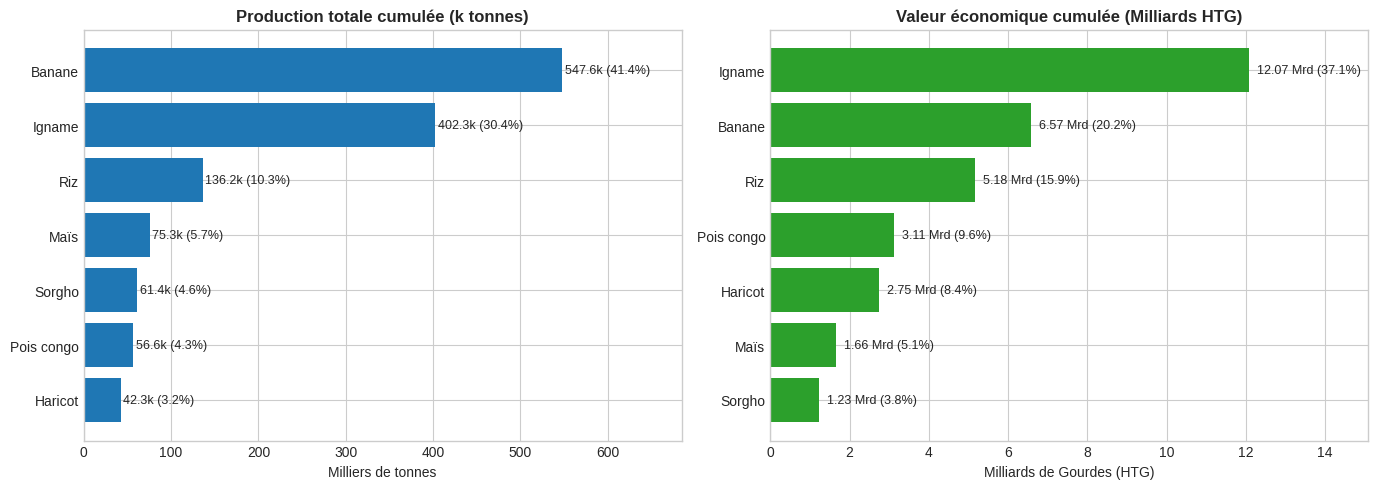

In [16]:
# Visualisation graphique comparative : Tonnes vs Valeur
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Production en tonnes (kilo-tonnes)
t_sorted = q1.sort_values('production_totale_t', ascending=True)
bars1 = ax1.barh(t_sorted['culture'], t_sorted['production_totale_t'] / 1000, color='#1f77b4')
ax1.set_title("Production totale cumulée (k tonnes)", fontweight='bold')
ax1.set_xlabel("Milliers de tonnes")
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 3, bar.get_y() + bar.get_height()/2, f"{w:.1f}k ({w*1000/q1['production_totale_t'].sum()*100:.1f}%)", va='center', fontsize=9)
ax1.set_xlim(0, (t_sorted['production_totale_t'].max() / 1000) * 1.25)

# Graphique 2 : Valeur économique en milliards de gourdes
v_sorted = q1.sort_values('valeur_milliards_htg', ascending=True)
bars2 = ax2.barh(v_sorted['culture'], v_sorted['valeur_milliards_htg'], color='#2ca02c')
ax2.set_title("Valeur économique cumulée (Milliards HTG)", fontweight='bold')
ax2.set_xlabel("Milliards de Gourdes (HTG)")
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.2, bar.get_y() + bar.get_height()/2, f"{w:.2f} Mrd ({w/q1['valeur_milliards_htg'].sum()*100:.1f}%)", va='center', fontsize=9)
ax2.set_xlim(0, v_sorted['valeur_milliards_htg'].max() * 1.25)

plt.show()


**Ce qu'on en conclut :**

Le classement change de manière spectaculaire entre la production physique (tonnage) et la valeur monétaire :
- **En volume**, la **banane** arrive largement en tête avec **547 615 tonnes (41,4 %)** du volume national, suivie de l'**igname (402 302 tonnes, 30,4 %)** et du **riz (136 225 tonnes, 10,3 %)**.
- **En valeur**, l'**igname** détrône la banane pour s'emparer de la 1ère place avec **12,07 milliards de gourdes (37,1 %)** de la valeur globale, contre **6,57 milliards HTG (20,2 %)** pour la banane. Cet écart s'explique par le prix au kilo : 30 HTG/kg pour l'igname contre 12 HTG/kg pour la banane.
- Les légumineuses illustrent encore plus nettement ce basculement : le **haricot**, bon dernier en tonnage (**7e rang**, 42 323 t, 3,2 %), remonte au **5e rang en valeur** (2,75 milliards HTG) grâce au prix au kilo le plus rémunérateur de toutes les cultures (**65 HTG/kg**). De même, le **pois congo** passe du 6e au 4e rang (3,11 milliards HTG à 55 HTG/kg). Les céréales (maïs et sorgho) rétrogradent en fin de classement en valeur.


## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

Nous calculons le rendement moyen pondéré (production cumulée divisée par la surface cumulée) par culture et département afin d'identifier les terroirs les plus performants et les zones en difficulté.


In [17]:
# Calcul des rendements par culture et département
rend_dept = complet.groupby(['culture', 'departement']).agg(
    prod_t=('production_t', 'sum'),
    surf_ha=('surface_ha', 'sum')
).reset_index()
rend_dept['rendement_t_ha'] = rend_dept['prod_t'] / rend_dept['surf_ha']

# Identification des extrêmes (meilleur et pire département par culture)
recap_rend = []
for cult_nom, grp in rend_dept.groupby('culture'):
    meilleur = grp.loc[grp['rendement_t_ha'].idxmax()]
    pire = grp.loc[grp['rendement_t_ha'].idxmin()]
    ecart_pct = ((meilleur['rendement_t_ha'] - pire['rendement_t_ha']) / pire['rendement_t_ha']) * 100
    recap_rend.append({
        'Culture': cult_nom,
        'Meilleur Département': meilleur['departement'],
        'Rendement Max (t/ha)': round(meilleur['rendement_t_ha'], 2),
        'Département le plus faible': pire['departement'],
        'Rendement Min (t/ha)': round(pire['rendement_t_ha'], 2),
        'Écart relatif (%)': round(ecart_pct, 1)
    })

df_recap = pd.DataFrame(recap_rend)
print(df_recap.to_string(index=False))


   Culture Meilleur Département  Rendement Max (t/ha) Département le plus faible  Rendement Min (t/ha)  Écart relatif (%)
    Banane                 Nord                  9.05                   Nord-Est                  6.23               45.4
   Haricot                  Sud                  0.88                 Nord-Ouest                  0.60               46.8
    Igname           Grand'Anse                  8.24                     Nippes                  5.30               55.3
      Maïs               Centre                  1.20                   Nord-Est                  0.91               32.5
Pois congo           Nord-Ouest                  1.01                   Nord-Est                  0.63               61.1
       Riz           Artibonite                  3.80                   Nord-Est                  2.12               79.1
    Sorgho               Centre                  1.08                   Nord-Est                  0.77               40.1


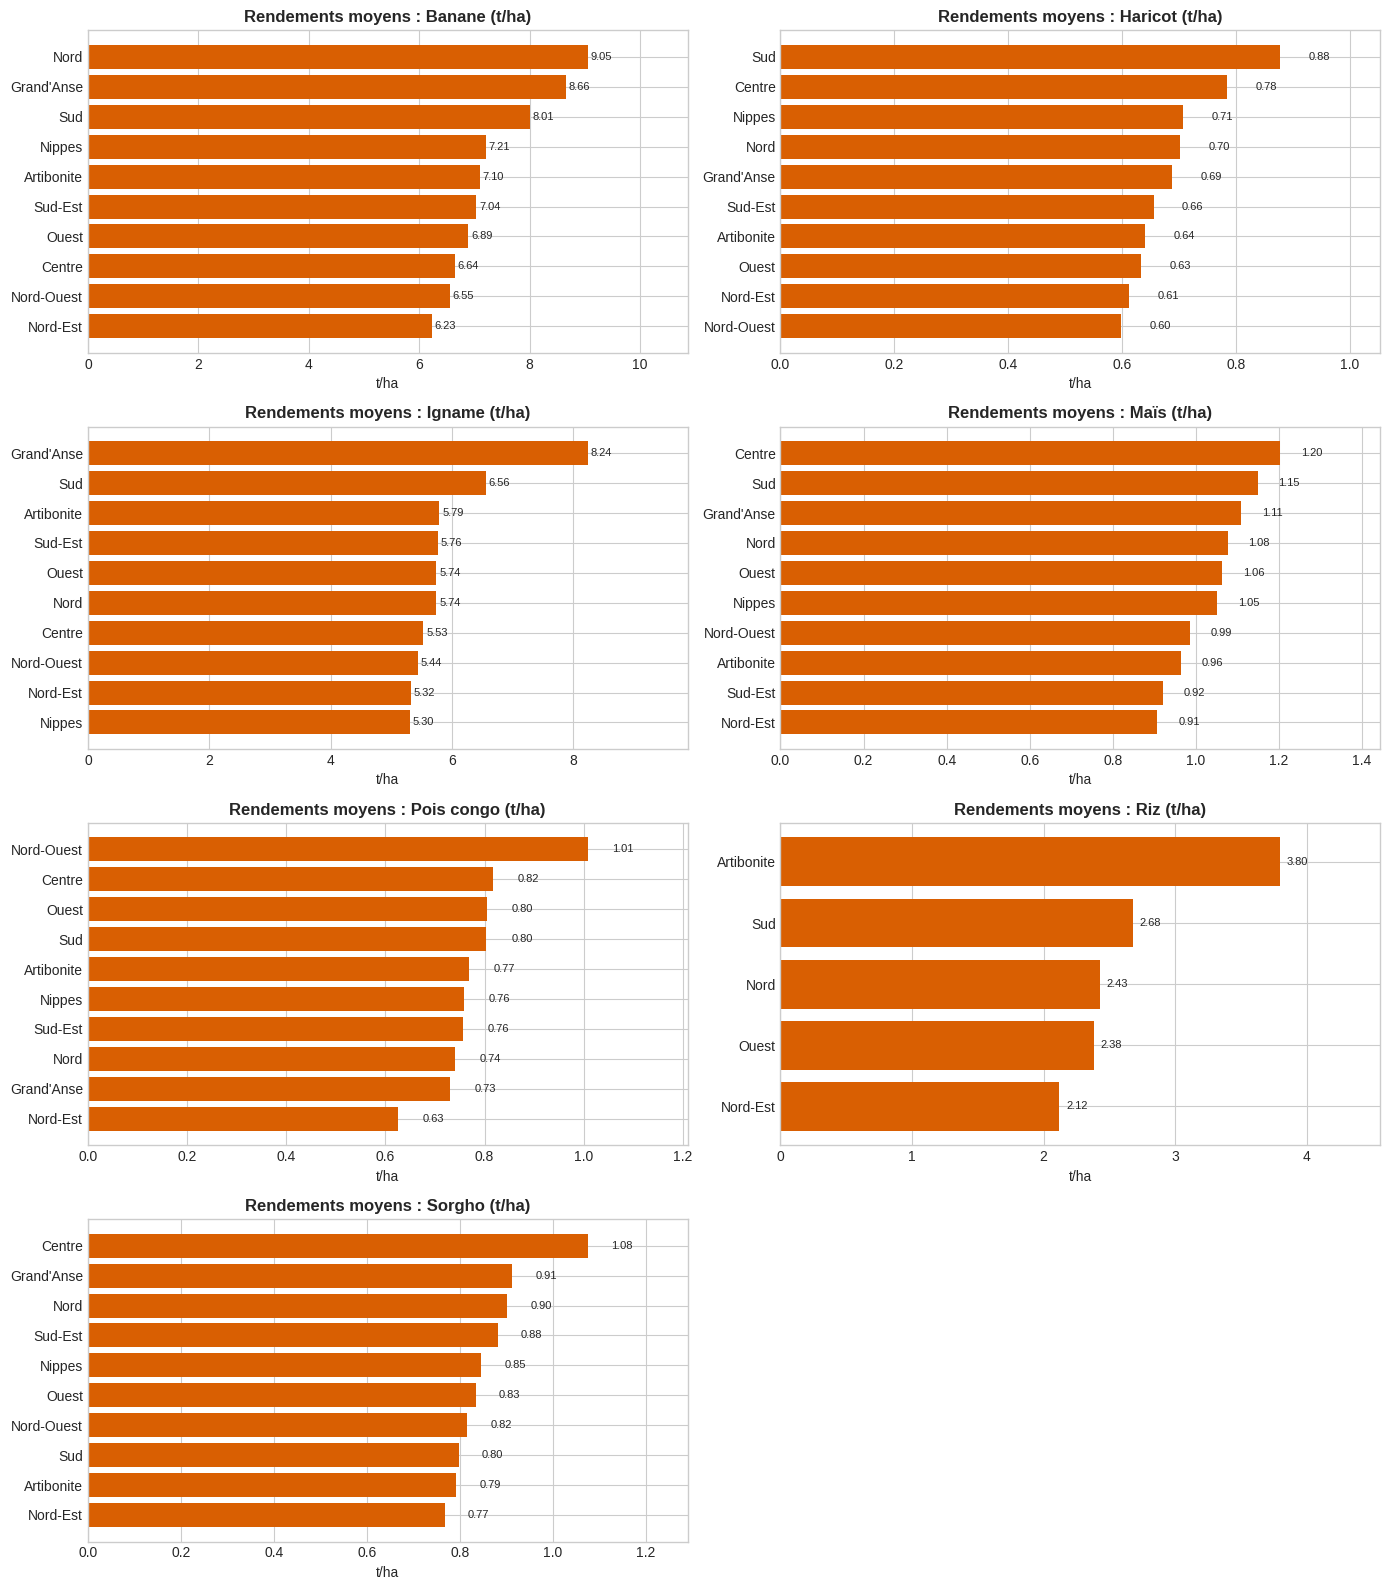

In [18]:
# Graphique en barres horizontales pour chaque culture
cultures_list = df_recap['Culture'].tolist()
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for idx, c in enumerate(cultures_list):
    ax = axes[idx]
    sub = rend_dept[rend_dept['culture'] == c].sort_values('rendement_t_ha', ascending=True)
    bars = ax.barh(sub['departement'], sub['rendement_t_ha'], color='#d95f02')
    ax.set_title(f"Rendements moyens : {c} (t/ha)", fontweight='bold')
    ax.set_xlabel("t/ha")
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', fontsize=8)
    ax.set_xlim(0, sub['rendement_t_ha'].max() * 1.2)

# Supprimer le 8e sous-graphique inutilisé
fig.delaxes(axes[7])
plt.show()


**Ce qu'on en conclut :**

Les rendements agricoles révèlent des spécialisations géographiques marquées :
- **Riz** : L'**Artibonite** affiche de loin le meilleur rendement national avec **3,80 t/ha**, surpassant de +79 % le Nord-Est (2,12 t/ha). Cela reflète l'atout stratégique des réseaux d'irrigation de la plaine de l'Artibonite.
- **Céréales sèches (Maïs & Sorgho)** : Le département du **Centre** s'adjuge la 1ère place tant pour le maïs (**1,20 t/ha**) que pour le sorgho (**1,08 t/ha**), valorisant son plateau agricole continental.
- **Légumineuses** : Le **Sud** mène pour le haricot (**0,88 t/ha**), tandis que le **Nord-Ouest** obtient le meilleur rendement pour le pois congo (**1,01 t/ha**).
- **Banane & Igname** : Le **Nord** domine la banane avec **9,05 t/ha**, tandis que la **Grand'Anse** domine l'igname avec **8,24 t/ha**.
- **Point critique** : Le département du **Nord-Est** arrive en dernière position pour 5 des 7 cultures (Maïs, Sorgho, Riz, Pois congo, Banane), soulignant une vulnérabilité agronomique majeure qui réclame des investissements ciblés en fertilité des sols et gestion de l'eau.


## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

Nous analysons la relation entre les précipitations saisonnières (`pluie_mm`) et le rendement réel (`rendement_t_ha`) pour chaque culture à travers le calcul des coefficients de corrélation linéaire de Pearson et le tracé de nuages de points avec droites de régression.


In [19]:
# Calcul des coefficients de corrélation de Pearson
correlations = []
for c in sorted(complet['culture'].unique()):
    sub = complet[complet['culture'] == c]
    r = sub['pluie_mm'].corr(sub['rendement_t_ha'])
    correlations.append({
        'Culture': c,
        'Observations (N)': len(sub),
        'Corrélation Pearson (r)': round(r, 3),
        'Sensibilité à la pluie': 'Très forte' if r > 0.7 else ('Forte' if r > 0.6 else ('Modérée' if r > 0.4 else 'Faible'))
    })

df_corr = pd.DataFrame(correlations).sort_values('Corrélation Pearson (r)', ascending=False)
print(df_corr.to_string(index=False))


   Culture  Observations (N)  Corrélation Pearson (r) Sensibilité à la pluie
   Haricot                56                    0.761             Très forte
      Maïs                58                    0.755             Très forte
    Igname                59                    0.694                  Forte
    Sorgho                56                    0.684                  Forte
    Banane                59                    0.645                  Forte
Pois congo                58                    0.627                  Forte
       Riz                30                    0.423                Modérée


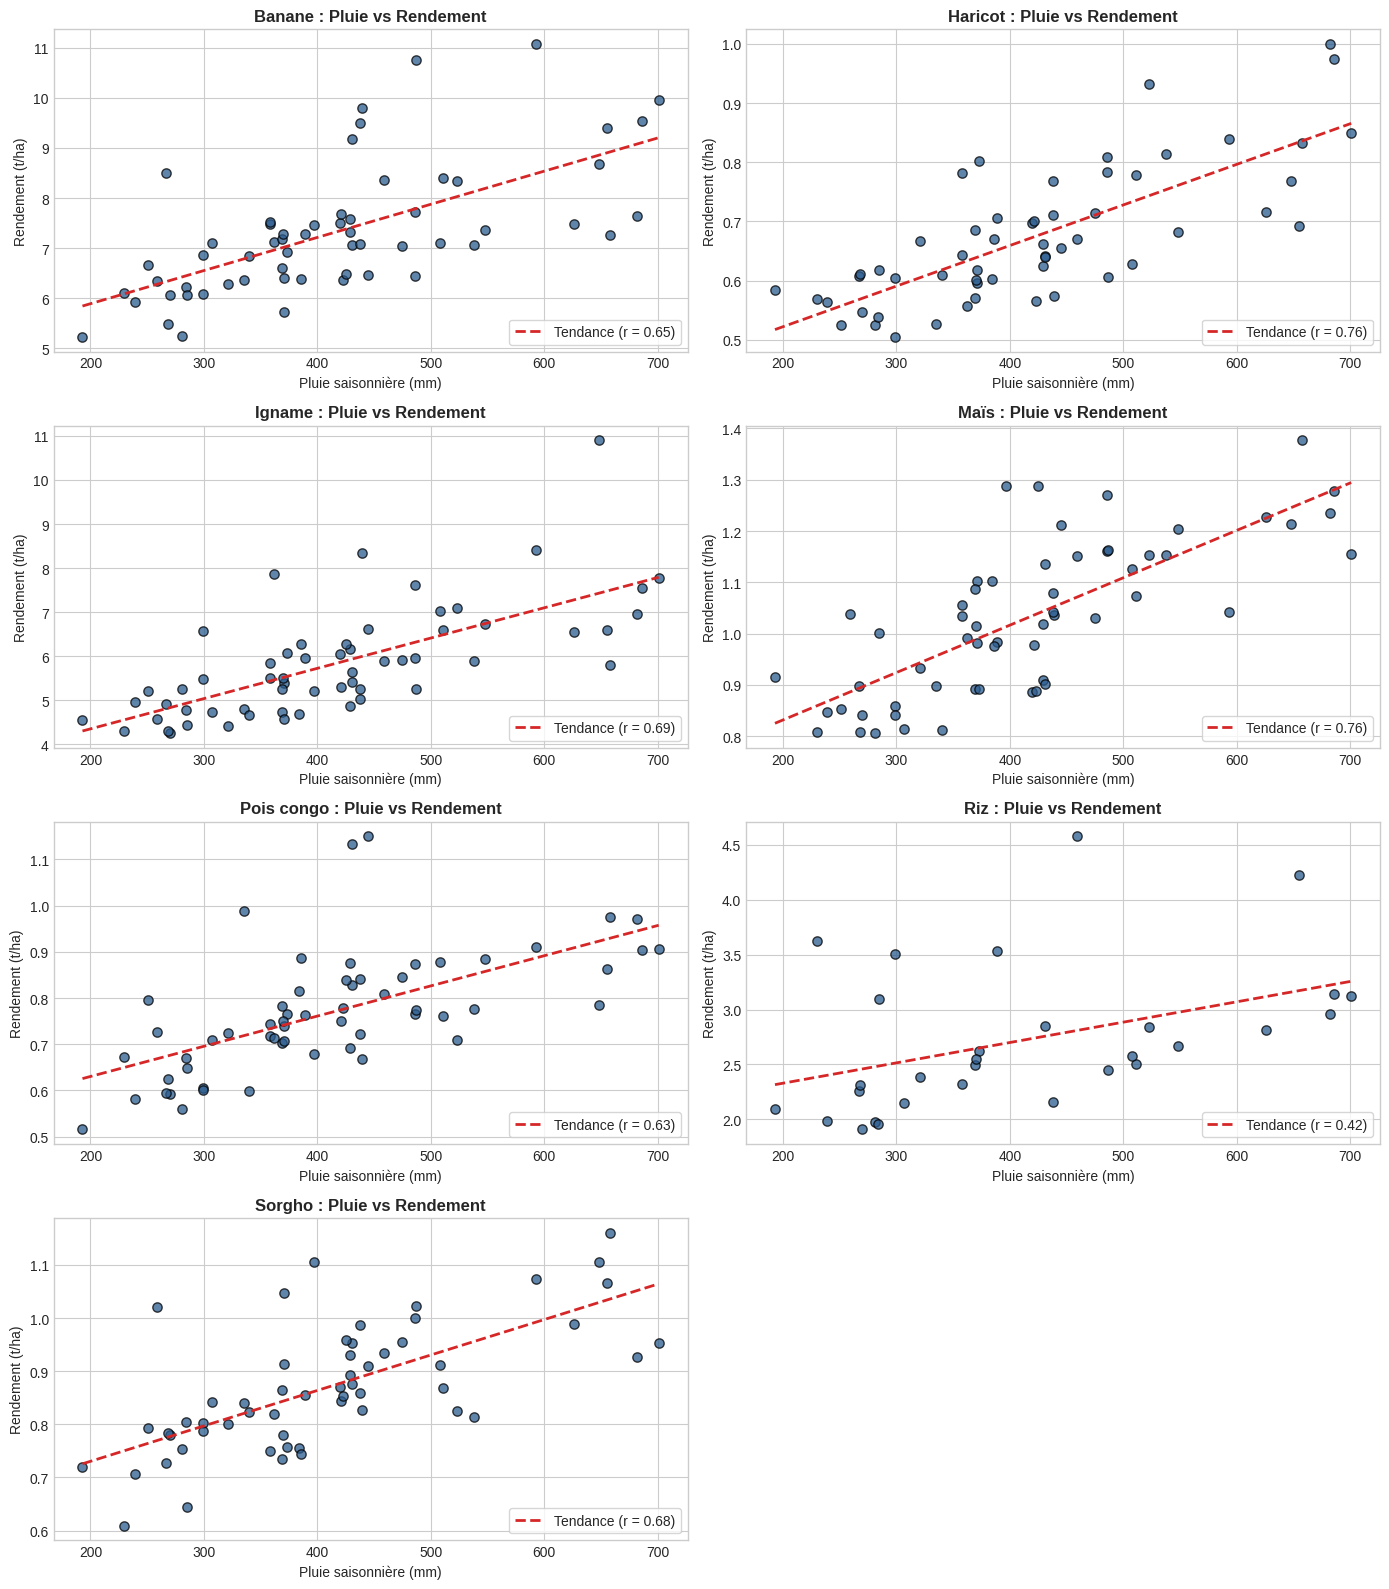

In [20]:
# Nuages de points avec droites de tendance linéaire pour chaque culture
cultures_uniques = sorted(complet['culture'].unique())
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for idx, c in enumerate(cultures_uniques):
    ax = axes[idx]
    sub = complet[complet['culture'] == c]
    x = sub['pluie_mm']
    y = sub['rendement_t_ha']
    r_val = x.corr(y)
    
    # Scatter plot
    ax.scatter(x, y, alpha=0.75, edgecolors='k', color='#2b5c8f', s=45)
    
    # Droite de tendance
    m, b = np.polyfit(x, y, 1)
    x_grid = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_grid, m * x_grid + b, color='#d62728', linestyle='--', linewidth=2, label=f"Tendance (r = {r_val:.2f})")
    
    ax.set_title(f"{c} : Pluie vs Rendement", fontweight='bold')
    ax.set_xlabel("Pluie saisonnière (mm)")
    ax.set_ylabel("Rendement (t/ha)")
    ax.legend(loc='lower right', frameon=True)

fig.delaxes(axes[7])
plt.show()


**Ce qu'on en conclut :**

La pluie explique de manière déterminante les rendements des cultures vivrières pluviales, mais son pouvoir explicatif varie selon les systèmes de culture :
1. **Forte dépendance pluviale (r > 0,70)** : Le **haricot (r = 0,761)** et le **maïs (r = 0,755)** sont extrêmement sensibles au régime des pluies. Pour ces cultures à cycle court et racines superficielles, un déficit pluviométrique se traduit immédiatement par une chute drastique du rendement.
2. **Dépendance modérée à forte (r entre 0,60 et 0,70)** : L'**igname (r = 0,694)**, le **sorgho (r = 0,684)**, la **banane (r = 0,645)** et le **pois congo (r = 0,627)** bénéficient d'une corrélation substantielle mais sont légèrement plus résilients grâce à des systèmes racinaires plus profonds ou une meilleure tolérance hydrique.
3. **Cas particulier du riz (r = 0,423)** : La corrélation est nettement plus faible. Cela confirme que la production de riz en Haïti est concentrée dans l'Artibonite où elle repose sur des périmètres d'irrigation alimentés par le système hydrographique du fleuve Artibonite, ce qui déconnecte partiellement les rendements des précipitations locales immédiates.


## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

Nous comparons l'évolution globale de la production en tonnes, des superficies emblavées en hectares et des rendements moyens entre la première année (2023) et la dernière année (2025).


In [21]:
# Tableau comparatif de l'évolution de la production
evol_prod = complet.pivot_table(index='culture', columns='annee', values='production_t', aggfunc='sum')
evol_prod['diff_tonnes'] = evol_prod[2025] - evol_prod[2023]
evol_prod['croissance_%'] = ((evol_prod[2025] - evol_prod[2023]) / evol_prod[2023]) * 100

# Tableau de l'évolution des surfaces cultivées
evol_surf = complet.pivot_table(index='culture', columns='annee', values='surface_ha', aggfunc='sum')
evol_surf['diff_surface_ha'] = evol_surf[2025] - evol_surf[2023]
evol_surf['diff_surface_%'] = ((evol_surf[2025] - evol_surf[2023]) / evol_surf[2023]) * 100

# Tableau de l'évolution des rendements
evol_rend = complet.pivot_table(index='culture', columns='annee', values='rendement_t_ha', aggfunc='mean')
evol_rend['diff_rend_%'] = ((evol_rend[2025] - evol_rend[2023]) / evol_rend[2023]) * 100

# Synthèse globale
bilan_evol = pd.DataFrame({
    'Prod 2023 (t)': evol_prod[2023],
    'Prod 2024 (t)': evol_prod[2024],
    'Prod 2025 (t)': evol_prod[2025],
    'Croissance Prod (%)': evol_prod['croissance_%'].round(1),
    'Variation Prod (t)': evol_prod['diff_tonnes'].round(0),
    'Évolution Surface (%)': evol_surf['diff_surface_%'].round(1),
    'Évolution Rendement (%)': evol_rend['diff_rend_%'].round(1)
}).sort_values('Croissance Prod (%)', ascending=False)

print(bilan_evol.to_string())


            Prod 2023 (t)  Prod 2024 (t)  Prod 2025 (t)  Croissance Prod (%)  Variation Prod (t)  Évolution Surface (%)  Évolution Rendement (%)
culture                                                                                                                                         
Riz               44064.0        39660.0        52501.0                 19.1              8437.0                    4.1                      3.3
Sorgho            20478.0        16785.0        24091.0                 17.6              3613.0                   17.5                     -0.4
Banane           182892.0       166401.0       198322.0                  8.4             15430.0                    2.6                      4.9
Pois congo        17484.0        22271.0        16871.0                 -3.5              -613.0                   -5.1                      3.3
Maïs              27006.0        24333.0        23972.0                -11.2             -3034.0                  -16.8           

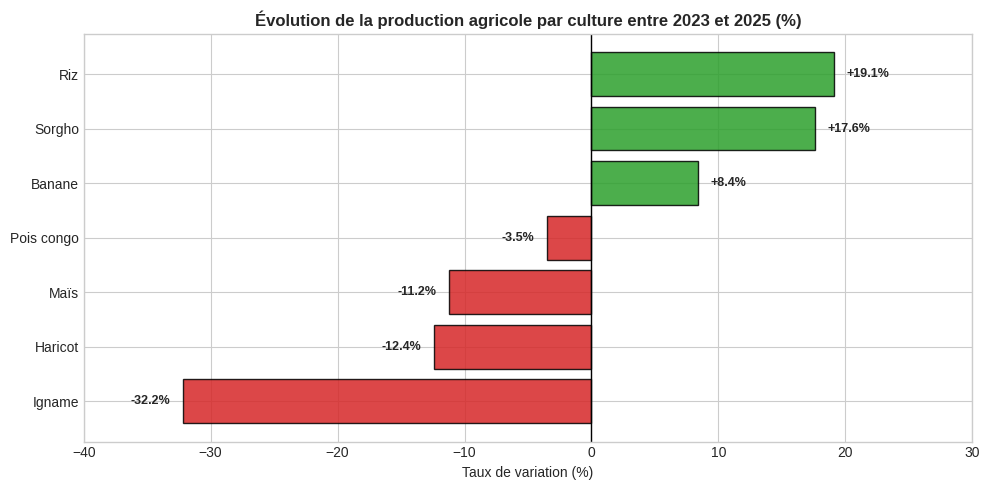

In [22]:
# Visualisation des taux de variation
fig, ax = plt.subplots(figsize=(10, 5))
croiss_sorted = bilan_evol.sort_values('Croissance Prod (%)', ascending=True)
couleurs = ['#2ca02c' if x >= 0 else '#d62728' for x in croiss_sorted['Croissance Prod (%)']]

bars = ax.barh(croiss_sorted.index, croiss_sorted['Croissance Prod (%)'], color=couleurs, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=1)
ax.set_title("Évolution de la production agricole par culture entre 2023 et 2025 (%)", fontweight='bold')
ax.set_xlabel("Taux de variation (%)")

for bar in bars:
    w = bar.get_width()
    va = 'left' if w >= 0 else 'right'
    offset = 1.0 if w >= 0 else -1.0
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha=va, fontweight='bold', fontsize=9)

ax.set_xlim(-40, 30)
plt.show()


**Ce qu'on en conclut :**

Entre 2023 et 2025, deux groupes distincts se dégagent nettement :
- **Cultures en forte progression** :
  - Le **Riz (+19,1 %, +8 437 tonnes)** : progression portée conjointement par l'expansion des surfaces (+4,1 %) et l'amélioration du rendement moyen (+3,3 %).
  - Le **Sorgho (+17,6 %, +3 613 tonnes)** : essor stimulé par une hausse massive des superficies semées (+17,5 %), traduisant un regain d'intérêt pour cette céréale rustique.
  - La **Banane (+8,4 %, +15 430 tonnes)** : solide gain de volume favorisé par la hausse constante des rendements (+4,9 %).
- **Cultures en net recul** :
  - L'**Igname (-32,2 %, soit une perte massive de 52 115 tonnes)** : c'est la crise la plus alarmante du secteur. Cette baisse découle directement d'un abandon de près d'un tiers des superficies cultivées (**-31,5 % de surface**, tombant de 27 341 ha à 18 739 ha).
  - Le **Haricot (-12,4 %, -1 998 tonnes)** et le **Maïs (-11,2 %, -3 034 tonnes)** : repli notable de la production, principalement dû à la baisse des surfaces emblavées (-8,2 % pour le haricot, -16,8 % pour le maïs).
  - Le **Pois congo (-3,5 %)** connaît un léger recul après un pic intermédiaire en 2024.


## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

Nous rapportons le tonnage cumulé de denrées récoltées sur les 3 ans à la population officielle de chaque département pour mesurer la disponibilité vivrière territoriale par habitant (en kg/habitant sur 3 ans et en moyenne annuelle).


In [23]:
# Agrégation de la production totale par département
q5 = complet.groupby(['departement', 'population', 'chef_lieu'])['production_t'].sum().reset_index()

# Conversion en kilogrammes et calcul par habitant
q5['prod_totale_kg'] = q5['production_t'] * 1000
q5['kg_par_habitant_3ans'] = q5['prod_totale_kg'] / q5['population']
q5['kg_par_habitant_an'] = q5['kg_par_habitant_3ans'] / 3.0

q5_classe = q5.sort_values('kg_par_habitant_an', ascending=False).reset_index(drop=True)
q5_classe['Rang'] = q5_classe.index + 1

tableau_q5 = q5_classe[['Rang', 'departement', 'chef_lieu', 'population', 'production_t', 'kg_par_habitant_3ans', 'kg_par_habitant_an']]
tableau_q5.columns = ['Rang', 'Département', 'Chef-lieu', 'Population', 'Production 3 ans (t)', 'Total 3 ans (kg/hab)', 'Moyenne (kg/hab/an)']
print(tableau_q5.to_string(index=False))


 Rang Département      Chef-lieu  Population  Production 3 ans (t)  Total 3 ans (kg/hab)  Moyenne (kg/hab/an)
    1  Grand'Anse        Jérémie      468301              114384.0            244.253162            81.417721
    2      Centre         Hinche      746236              167080.0            223.896998            74.632333
    3         Sud      Les Cayes      774976              155168.0            200.222975            66.740992
    4    Nord-Est   Fort-Liberté      393967               75030.0            190.447423            63.482474
    5  Artibonite       Gonaïves     1727524              269226.0            155.845013            51.948338
    6      Nippes      Miragoâne      342525               49223.0            143.706299            47.902100
    7     Sud-Est         Jacmel      632601               80796.0            127.720317            42.573439
    8  Nord-Ouest   Port-de-Paix      728807               87192.0            119.636612            39.878871
    9     

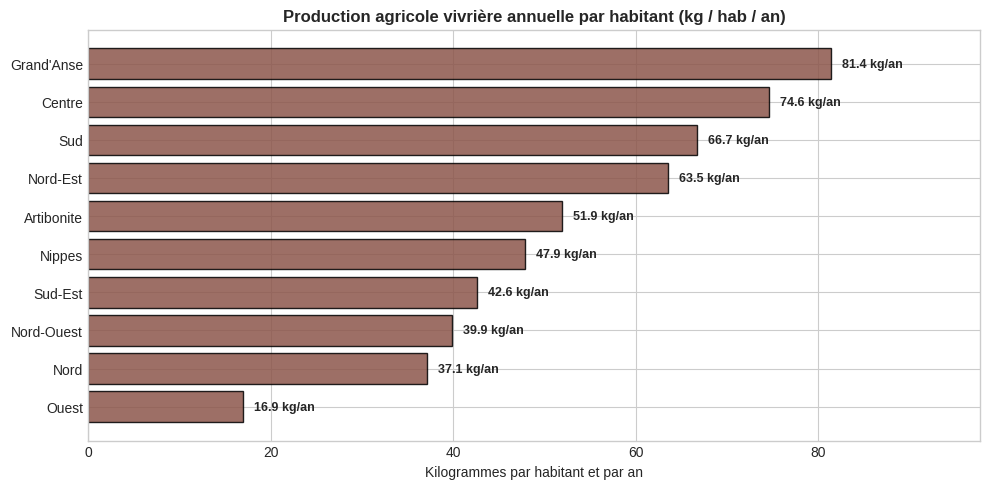

In [24]:
# Graphique en barres de la production par habitant
fig, ax = plt.subplots(figsize=(10, 5))
q5_plot = q5_classe.sort_values('kg_par_habitant_an', ascending=True)

bars = ax.barh(q5_plot['departement'], q5_plot['kg_par_habitant_an'], color='#8c564b', edgecolor='black', alpha=0.85)
ax.set_title("Production agricole vivrière annuelle par habitant (kg / hab / an)", fontweight='bold')
ax.set_xlabel("Kilogrammes par habitant et par an")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1.2, bar.get_y() + bar.get_height()/2, f"{w:.1f} kg/an", va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, q5_plot['kg_par_habitant_an'].max() * 1.2)
plt.show()


**Ce qu'on en conclut :**

Le ratio de production par habitant met en relief une profonde asymétrie territoriale :
- Les **grands greniers vivriers** sont la **Grand'Anse (81,4 kg/hab/an)**, le **Centre (74,6 kg/hab/an)** et le **Sud (66,7 kg/hab/an)**. Grâce à une combinaison d'espaces agricoles fertiles et d'une densité de population modérée, ces départements dégagent des surplus alimentaires essentiels pour la sécurité nutritionnelle du pays.
- Le département de l'**Artibonite**, bien qu'étant le 1er producteur absolu en volume brut, se classe au 5e rang par habitant (**51,9 kg/hab/an**) en raison de sa population nombreuse (1,73 million d'habitants).
- À l'autre extrémité, le département de l'**Ouest** ferme la marche avec seulement **16,9 kg/hab/an** (50,8 kg sur 3 ans). Abrégeant plus de 4 millions d'habitants (près de 40 % de la population nationale) sur un espace urbain dense à Port-au-Prince, l'Ouest souffre d'un déficit alimentaire structurel massif et dépend entièrement des axes de transport pour acheminer les denrées depuis les provinces.


## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.


1. **Ce qu'il faut retenir :** Si la banane mène les tonnages physiques (41 % du volume), l'igname constitue le véritable pilier économique (37 % de la valeur marchande, 12 Mrd HTG), tandis que la Grand'Anse et le Centre s'affirment comme les greniers vivriers majeurs face à un département de l'Ouest hyper-déficitaire (17 kg/hab/an).
2. **Ce qu'il faut retenir (climat) :** La pluviométrie régit étroitement les rendements des denrées pluviales de base comme le maïs et le haricot (r > 0,75), contrastant avec le riz dont la productivité est sécurisée par l'irrigation de la vallée de l'Artibonite (3,80 t/ha).
3. **Ce qu'il faut retenir (alerte filière) :** La violente chute de 32 % de la récolte d'igname entre 2023 et 2025, consécutive à l'abandon d'un tiers des surfaces cultivées, signale une fragilisation aiguë du revenu des ménages agricoles.
4. **Ce que les données ne permettent pas de dire :** En se limitant aux volumes récoltés et à des prix fixes nationaux, ce jeu de données ne renseigne ni sur les coûts de production (engrais, semences, main-d'œuvre), ni sur l'inflation galopante, ni sur les pertes après récolte subies lors du transport.
5. **Ce qu'il faudrait mesurer ensuite :** Il est impératif d'enquêter sur les marges nettes des exploitants, d'installer un suivi hydrologique et satellitaire par commune pour anticiper les sécheresses, et de cartographier l'état des axes routiers pour désenclaver les surplus du Grand Sud vers la capitale.
